## RQ2: 
### Considering unit traffic exposure, is the risk of fatal and serious accident associated with posted speed limit near SCATS-monitored intersections

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import pyarrow
import warnings
import geopandas as gpd
from IPython.display import clear_output
from pathlib import Path
from datetime import time
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, average_precision_score, balanced_accuracy_score)

THE_ANSWER = 42

### Output style (optional)

In [3]:
plt.style.use("tableau-colorblind10")
import matplotlib as mpl
from matplotlib import font_manager
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
if ("IBM Plex Mono" in available_fonts):
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["IBM Plex Mono"],
        "font.monospace": ["IBM Plex Mono"],
        "axes.unicode_minus": False,
        "font.size": 12,
        "figure.dpi": 120,
    })

### Data check

In [4]:
df = pd.read_parquet("rq1.parquet")
print(df.shape)

assert(df.shape == (195523, 98))

(195523, 98)


### Data overview

#### Re-fetch datetime information from `accident_rq1.csv`

In [36]:
acc_df = pd.read_csv("data/accident_rq1.csv")
acc_df["DATETIME"] = pd.to_datetime(acc_df["ACCIDENT_DATE"] + " " + acc_df["ACCIDENT_TIME"])

df = pd.read_parquet("rq1.parquet")
df = df.merge(acc_df[["ACCIDENT_NO", "DATETIME"]], on="ACCIDENT_NO", how="left")
df = df[df["DATETIME"] >= "2014-01-01"]
print(df.shape)

(167625, 99)


#### Re-fetch location information from `node.csv`

In [37]:
node_df = pd.read_csv("data/raw/node.csv")
loc_df = pd.read_csv("data/raw/accident_location.csv")
site_df = pd.read_csv("victorian_traffic_signals.csv")

loc_node = loc_df.merge(
    node_df[["NODE_ID", "LATITUDE", "LONGITUDE"]],
    on="NODE_ID",
    how="left"
)

loc_node = loc_node[
    loc_node["LATITUDE"].notna()
    & loc_node["LONGITUDE"].notna()
    & (loc_node["LATITUDE"] != 0)
    & (loc_node["LONGITUDE"] != 0)
].copy()

loc_node["_dist_sort"] = loc_node["DISTANCE_LOCATION"].fillna(float("inf"))

best_node = (
    loc_node
    .sort_values(["ACCIDENT_NO", "_dist_sort"])
    .drop_duplicates("ACCIDENT_NO", keep="first")
    .drop(columns=["_dist_sort"])
)

acc_gdf = gpd.GeoDataFrame(
    best_node[["ACCIDENT_NO", "LATITUDE", "LONGITUDE"]],
    geometry=gpd.points_from_xy(best_node["LONGITUDE"], best_node["LATITUDE"]),
    crs="EPSG:4326"
).to_crs("EPSG:7855")

site_gdf = gpd.GeoDataFrame(
    site_df[["SITE_NO", "LATITUDE", "LONGITUDE"]],
    geometry=gpd.points_from_xy(site_df["LONGITUDE"], site_df["LATITUDE"]),
    crs="EPSG:4326"
).to_crs("EPSG:7855")

# Nearest site
acc_site = gpd.sjoin_nearest(
    acc_gdf,
    site_gdf[["SITE_NO", "geometry"]],
    how="left",
    distance_col="DIST_TO_SITE_M"
)

# Only keep within 100m
acc_site_100m = acc_site[
    acc_site["DIST_TO_SITE_M"] <= 150
].copy()

# 
accident_site = (
    acc_site_100m[["ACCIDENT_NO", "SITE_NO"]]
    .drop_duplicates("ACCIDENT_NO")
    .reset_index(drop=True)
)

accident_site["SITE_NO"] = accident_site["SITE_NO"].astype("int32")

df = df.merge(
    accident_site,
    on="ACCIDENT_NO",
    how="inner"
)

print(df.shape)

df.to_parquet("rq2_acc.parquet")

(68799, 100)


#### Check DateTime range to decide how much SCATS data is needed

In [38]:
print(f"Earliest: {df["DATETIME"].min()}\nLatest: {df["DATETIME"].max()}")

Earliest: 2014-01-01 01:30:00
Latest: 2025-08-31 18:40:00


#### SCATS data starts from 2024-01-01 and can be capped at 2025-08-31

In [22]:
scat_meta_df = pd.read_csv("victorian_traffic_signals.csv")
scat_test_df = pd.read_csv("scats/VSDATA_20250831.csv")

site_ids = set(scat_meta_df["SITE_NO"].dropna().astype(int))
scats_ids = set(scat_test_df["NB_SCATS_SITE"].dropna().astype(int))

print(len(site_ids), len(scats_ids), len(site_ids & scats_ids))
coverage = len(site_ids & scats_ids) / len(scats_ids)
print(f"SCATS volume sites covered by metadata: {coverage:.2%}")

V_COLS = [f"V{i:02d}" for i in range(96)]
AM_PEAK_COLS = [f"V{i:02d}" for i in range(28, 36)]  # 07-09
PM_PEAK_COLS = [f"V{i:02d}" for i in range(64, 72)]  # 16-18

def assemble_df(csv):
    expected_cols = [
        "NB_SCATS_SITE",     # intersection number (SITE_ID)
        "QT_INTERVAL_COUNT", # date reading
        "NB_DETECTOR",       # detector number     (DETECTOR_ID)
        *V_COLS,             # volume (15 min increments)
        "NM_REGION",         # SCATS region
        "CT_RECORDS",        # count of number of 15 min where data exists
        "QT_VOLUME_24HOUR",  # sum of vol recorded within the day
        "CT_ALARM_24HOUR",   # count of alarms within the dayc 
    ]
    df = pd.read_csv(csv, engine="pyarrow")
    assert(set(expected_cols) <= set(df.columns))
    

    # Standardise ID
    df["NB_SCATS_SITE"] = pd.to_numeric(df["NB_SCATS_SITE"], errors="coerce").astype("Int64")
    df["NB_DETECTOR"] = pd.to_numeric(df["NB_DETECTOR"], errors="coerce").astype("Int64")

    # Extract date
    df["DATE"] = pd.to_datetime(
        df["QT_INTERVAL_COUNT"],
        format="%Y-%m-%d %H:%M:%S.%f",
        errors="coerce"
    ).dt.normalize()

    # Numerical vals
    numeric_cols = [
        *V_COLS,
        "CT_RECORDS",
        "QT_VOLUME_24HOUR",
        "CT_ALARM_24HOUR",
    ]
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Manually calculate volume sum
    df.drop(columns=["QT_VOLUME_24HOUR"], inplace=True)
    v = df[V_COLS].mask(df[V_COLS].lt(0), np.nan)
    df["NUM_VALID_V"] = v.notna().sum(axis=1).astype("int32")
    df["SUM_VALID_V"] = v.sum(axis=1, skipna=True, min_count=1)

    # Keep raw metadata before cleaning
    keys = ["NB_SCATS_SITE", "DATE"]
    raw_meta = (
        df.groupby(keys, dropna=False)
        .agg(
            NUM_RAW_DETECTOR=("NB_DETECTOR", "nunique"),
            NUM_RAW_ROWS=("NB_DETECTOR", "size"),
        )
        .reset_index()
    )

    # Drop severely incomplete detector row
    valid = df["NUM_VALID_V"] >= 90
    df = df.loc[valid].copy()
    v = v.loc[valid]

    # Calculate per site sum
    site_v = (
        v.groupby([df["NB_SCATS_SITE"], df["DATE"]], dropna=False, observed=True)
        .sum(min_count=1)
        .reset_index()
    )

    site_v["SUM_VALID_V_SITE"] = site_v[V_COLS].sum(axis=1, skipna=True)
    site_v["V_AM_PEAK"] = site_v[AM_PEAK_COLS].sum(axis=1, skipna=True)
    site_v["V_PM_PEAK"] = site_v[PM_PEAK_COLS].sum(axis=1, skipna=True)
    site_v["V_15M_MAX"] = site_v[V_COLS].max(axis=1, skipna=True)
    site_v["V_15M_STD"] = site_v[V_COLS].std(axis=1, skipna=True)

    # Aggregate by day
    meta = (
        df.groupby(keys, dropna=False, observed=True)
        .agg(
            NUM_VALID_V=("NUM_VALID_V", "sum"),
            NUM_VALID_DETECTOR=("NB_DETECTOR", "nunique"),
            MIN_RECORDS=("CT_RECORDS", "min"),
            MEAN_RECORDS=("CT_RECORDS", "mean"),
            REGION=("NM_REGION", "first"),
        )
        .reset_index()
    )

    # Keep number of all data (including invalid)
    meta = meta.merge(
        raw_meta,
        on=keys,
        how="left"
    )

    site_day = site_v[
        ["NB_SCATS_SITE", "DATE", "SUM_VALID_V_SITE", "V_AM_PEAK", "V_PM_PEAK", "V_15M_MAX", "V_15M_STD"]
    ].merge(
        meta,
        on=keys,
        how="left"
    ).rename(columns={"NB_SCATS_SITE": "SITE_NO", "SUM_VALID_V_SITE": "SUM_VALID_V"})

    site_day = site_day.dropna(subset=["SITE_NO", "DATE"])
    site_day["SITE_NO"] = site_day["SITE_NO"].astype("int32")

    # Quality assurance
    site_day["EXPECTED_NUM_V"] = site_day["NUM_VALID_DETECTOR"] * 96

    site_day["COMPLETENESS"] = (
        site_day["NUM_VALID_V"] / site_day["EXPECTED_NUM_V"]
    )

    site_day["V_24H_ADJ"] = (
        site_day["SUM_VALID_V"]
        * site_day["EXPECTED_NUM_V"]
        / site_day["NUM_VALID_V"]
    )

    site_day.loc[
        site_day["COMPLETENESS"] < 0.95,
        "V_24H_ADJ"
    ] = np.nan

    site_day["DETECTOR_RETENTION"] = (
        site_day["NUM_VALID_DETECTOR"] / site_day["NUM_RAW_DETECTOR"]
    )

    return site_day.copy()

site_day = assemble_df("scats/VSDATA_20150101.csv")
print(site_day.shape)
print(site_day.columns)
print(site_day.describe())
print("Missing V_24H_ADJ:", site_day["V_24H_ADJ"].isna().mean())
print("Zero observed volume:", (site_day["SUM_VALID_V"] == 0).mean())
print("Low completeness:", (site_day["COMPLETENESS"] < 0.95).mean())
print("Low detector retention:", (site_day["DETECTOR_RETENTION"] < 0.8).mean())

5001 4656 4439
SCATS volume sites covered by metadata: 95.34%
(3412, 18)
Index(['SITE_NO', 'DATE', 'SUM_VALID_V', 'V_AM_PEAK', 'V_PM_PEAK', 'V_15M_MAX',
       'V_15M_STD', 'NUM_VALID_V', 'NUM_VALID_DETECTOR', 'MIN_RECORDS',
       'MEAN_RECORDS', 'REGION', 'NUM_RAW_DETECTOR', 'NUM_RAW_ROWS',
       'EXPECTED_NUM_V', 'COMPLETENESS', 'V_24H_ADJ', 'DETECTOR_RETENTION'],
      dtype='str')
           SITE_NO                 DATE    SUM_VALID_V    V_AM_PEAK  \
count  3412.000000                 3412    3412.000000  3412.000000   
mean   3075.041618  2015-01-01 00:00:00   20381.705451   717.388628   
min     100.000000  2015-01-01 00:00:00       0.000000     0.000000   
25%    1246.750000  2015-01-01 00:00:00   11084.750000   357.000000   
50%    3277.500000  2015-01-01 00:00:00   17257.500000   562.000000   
75%    4467.250000  2015-01-01 00:00:00   25977.250000   870.500000   
max    7667.000000  2015-01-01 00:00:00  111677.000000  8617.000000   
std    1763.352092                  NaN   

/tmp/ipykernel_17756/4069872662.py:54: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["NUM_VALID_V"] = v.notna().sum(axis=1).astype("int32")
/tmp/ipykernel_17756/4069872662.py:55: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["SUM_VALID_V"] = v.sum(axis=1, skipna=True, min_count=1)
/tmp/ipykernel_17756/4069872662.py:83: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1)

### Read all SCATS agg to site x day

In [23]:
site_days = []
errs = []


with warnings.catch_warnings():
    warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
    paths = sorted(Path("scats").glob("*.csv"))
    for i, csv_path in enumerate(paths):
        clear_output(wait=True)
        print(f"Loading {i}/{len(paths)} csv", flush=True)
        try:
            site_day = assemble_df(csv_path)
            site_day["SRC"] = csv_path.name
            site_days.append(site_day)
        except Exception as e:
            print(f"SRC: {csv_path.name}, ERR: {repr(e)}")
            errs.append({
                "SRC": csv_path.name,
                "ERR": repr(e)
            })

scats = pd.concat(site_days, ignore_index=True)
err_df = pd.DataFrame(errs)
print(err_df)
print(scats.shape)
err_df.to_csv("err.csv", index=False)
scats.to_parquet("scats.parquet", compression="zstd", index=False)

Loading 4251/4252 csv
Empty DataFrame
Columns: []
Index: []
(16805646, 19)


### Assign accident with SCAT IDs

In [46]:
acc_df = pd.read_parquet("rq2_acc.parquet")
scats_df = pd.read_parquet("scats.parquet")

# First aggregate accident by site-day
acc_df["FATAL_COUNT"] = (acc_df["SEVERITY"] == 1).astype("int16")
acc_df["SERIOUS_COUNT"] = (acc_df["SEVERITY"] == 2).astype("int16")
acc_df["FATAL_OR_SERIOUS_COUNT"] = (acc_df["SEVERITY"].isin([1, 2])).astype("int16")
acc_df["OTHER_INJ_COUNT"] = (acc_df["SEVERITY"] == 3).astype("int16")
acc_df["NO_INJ_COUNT"] = (acc_df["SEVERITY"] == 4).astype("int16")
acc_df["DATE"] = acc_df["DATETIME"].dt.normalize()

acc_site_day = (
    acc_df.groupby(["SITE_NO", "DATE"])
    .agg(
        ACCIDENT_COUNT = ("ACCIDENT_NO", "nunique"),
        FATAL_COUNT=("FATAL_COUNT", "sum"),
        SERIOUS_COUNT=("SERIOUS_COUNT", "sum"),
        FATAL_OR_SERIOUS_COUNT=("FATAL_OR_SERIOUS_COUNT", "sum"),
        OTHER_INJ_COUNT=("OTHER_INJ_COUNT", "sum"),
        NO_INJ_COUNT=("NO_INJ_COUNT", "sum")
    )
    .reset_index()
)

# Use mode as an indicating speed limit
def mode_or_na(x):
    m = x.dropna().mode()
    return m.iloc[0] if not m.empty else pd.NA

site_speed = (
    acc_df.groupby("SITE_NO")["SPEED_ZONE"]
    .agg(mode_or_na)
    .reset_index()
    .rename(columns={
        "SPEED_ZONE": "SITE_SPEED_ZONE_MODE"
    })
)

scats_df["DATE"] = pd.to_datetime(scats_df["DATE"]).dt.normalize()
acc_site_day["DATE"] = pd.to_datetime(acc_site_day["DATE"]).dt.normalize()

scats_df = scats_df.merge(
    acc_site_day,
    on=["SITE_NO", "DATE"],
    how="left"
)

count_cols = [
    "ACCIDENT_COUNT",
    "FATAL_COUNT",
    "SERIOUS_COUNT",
    "FATAL_OR_SERIOUS_COUNT",
    "OTHER_INJ_COUNT",
    "NO_INJ_COUNT"
]

scats_df[count_cols] = scats_df[count_cols].fillna(0)

for c in count_cols:
    scats_df[c] = scats_df[c].astype("int16")

scats_df = scats_df.merge(
    site_speed,
    on="SITE_NO",
    how="left"
)

# Remove sites without speed zone at all
scats_df = scats_df[scats_df["SITE_SPEED_ZONE_MODE"].notna()].copy()
scats_df["SITE_SPEED_ZONE_MODE"] = scats_df["SITE_SPEED_ZONE_MODE"].astype("int16")

print(scats_df)

          SITE_NO       DATE  SUM_VALID_V  V_AM_PEAK  V_PM_PEAK  V_15M_MAX  \
0             100 2014-01-01      14099.0      483.0     1818.0      300.0   
1             101 2014-01-01      12634.0      376.0     1810.0      305.0   
2             102 2014-01-01      20872.0      667.0     3399.0      557.0   
3             103 2014-01-01      10232.0      347.0     1592.0      274.0   
4             104 2014-01-01      25310.0      751.0     3914.0      812.0   
...           ...        ...          ...        ...        ...        ...   
16805629    32149 2025-08-31       5286.0      300.0      726.0      151.0   
16805630    32152 2025-08-31       8838.0      678.0     1369.0      239.0   
16805634    32160 2025-08-31      13541.0      348.0     2489.0      384.0   
16805635    32176 2025-08-31      20592.0      971.0     3212.0      569.0   
16805638    32182 2025-08-31       1424.0      106.0      186.0       49.0   

           V_15M_STD  NUM_VALID_V  NUM_VALID_DETECTOR  MIN_RECO

### Feature engineering

In [50]:
# Remove zero exposure entries since we are only studying per exposure
scats_df = scats_df[scats_df["V_24H_ADJ"] > 0].copy()

scats_df["EXPOSURE_VOLUME"] = scats_df["V_24H_ADJ"].astype("float64")
scats_df["LOG_EXPOSURE_VOLUME"] = np.log(scats_df["EXPOSURE_VOLUME"])

scats_df.to_parquet(
    "rq2.parquet",
    compression="zstd",
    index=False
)

print(scats_df.shape)
print(scats_df.dtypes)

(15923380, 28)
SITE_NO                            int32
DATE                      datetime64[ns]
SUM_VALID_V                      float64
V_AM_PEAK                        float64
V_PM_PEAK                        float64
V_15M_MAX                        float64
V_15M_STD                        float64
NUM_VALID_V                        int32
NUM_VALID_DETECTOR                 int64
MIN_RECORDS                      float64
MEAN_RECORDS                     float64
REGION                               str
NUM_RAW_DETECTOR                   int64
NUM_RAW_ROWS                       Int64
EXPECTED_NUM_V                     int64
COMPLETENESS                     float64
V_24H_ADJ                        float64
DETECTOR_RETENTION               float64
SRC                                  str
ACCIDENT_COUNT                     int16
FATAL_COUNT                        int16
SERIOUS_COUNT                      int16
FATAL_OR_SERIOUS_COUNT             int16
OTHER_INJ_COUNT                    int16
N

### Monthly classical models from `rq2.parquet`

This part directly loads the finished `rq2.parquet`, aggregates daily site-level rows into monthly site-level rows, then trains three classical models suggested for RQ2: `PoissonRegressor`, `RandomForestRegressor`, and `XGBoost`.

The monthly aggregation is used because fatal/serious accidents are very sparse at daily granularity, so monthly counts provide a more stable target.


#### Setup imports and locate the prepared parquet file

This cell imports only the packages needed for direct modelling and finds `rq2.parquet`. If you run the notebook inside the `a2` folder it uses `rq2.parquet`; if you run it from the project root it falls back to `a2/rq2.parquet`.


In [24]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
DATA_PATH = Path("rq2.parquet") if Path("rq2.parquet").exists() else Path("a2/rq2.parquet")
print(DATA_PATH.resolve())


D:\UniMelb\2026 s1\COMP 90049 Introduction to Machine Learning\A2\a2\rq2.parquet


#### Load `rq2.parquet` and check the columns

This reads the prepared RQ2 dataset. The output can use to confirm the file loaded correctly and that the expected columns, such as speed zone, exposure, and fatal/serious accident count, are present.


In [25]:
rq2_df = pd.read_parquet(DATA_PATH)
rq2_df.columns = rq2_df.columns.str.upper()

print(rq2_df.shape)
display(rq2_df.head())
print(rq2_df.dtypes)


(15920097, 22)


,SITE_NO,DATE,SUM_VALID_V,V_AM_PEAK,V_PM_PEAK,V_15M_MAX,V_15M_STD,NUM_VALID_V,NUM_VALID_DETECTOR,REGION,...,DETECTOR_RETENTION,ACCIDENT_COUNT,FATAL_COUNT,SERIOUS_COUNT,FATAL_OR_SERIOUS_COUNT,OTHER_INJ_COUNT,NO_INJ_COUNT,SITE_SPEED_ZONE_MODE,EXPOSURE_VOLUME,LOG_EXPOSURE_VOLUME
0,100,2014-01-01,14099.0,483.0,1818.0,300.0,83.173708,2304,24,WV1,...,1.0,0,0,0,0,0,0,80,14099.000000,9.553859
1,101,2014-01-01,12634.0,376.0,1810.0,305.0,87.406790,2298,24,MEN,...,1.0,0,0,0,0,0,0,60,12666.986945,9.446754
2,102,2014-01-01,20872.0,667.0,3399.0,557.0,182.821666,2298,24,CRN,...,1.0,0,0,0,0,0,0,80,20926.496084,9.948771
3,103,2014-01-01,10232.0,347.0,1592.0,274.0,81.964648,2304,24,CRN,...,1.0,0,0,0,0,0,0,50,10232.000000,9.233275
4,104,2014-01-01,25310.0,751.0,3914.0,812.0,270.678445,2304,24,VIC,...,1.0,0,0,0,0,0,0,50,25310.000000,10.138955


SITE_NO                            int32
DATE                      datetime64[us]
SUM_VALID_V                      float64
V_AM_PEAK                        float64
V_PM_PEAK                        float64
V_15M_MAX                        float64
V_15M_STD                        float64
NUM_VALID_V                        int32
NUM_VALID_DETECTOR                 int64
REGION                               str
NUM_RAW_DETECTOR                   int64
COMPLETENESS                     float64
DETECTOR_RETENTION               float64
ACCIDENT_COUNT                     int16
FATAL_COUNT                        int16
SERIOUS_COUNT                      int16
FATAL_OR_SERIOUS_COUNT             int16
OTHER_INJ_COUNT                    int16
NO_INJ_COUNT                       int16
SITE_SPEED_ZONE_MODE               int16
EXPOSURE_VOLUME                  float64
LOG_EXPOSURE_VOLUME              float64
dtype: object


#### Prepare daily rows for monthly aggregation

This cell standardises the key column names, creates month-related date features, removes rows without valid exposure, and checks that the columns needed for RQ2 exist.


In [26]:
daily_df = rq2_df.copy()

TARGET_COL = "FATAL_OR_SERIOUS_COUNT"
SPEED_COL = "SITE_SPEED_ZONE_MODE"
EXPOSURE_COL = "EXPOSURE_VOLUME" if "EXPOSURE_VOLUME" in daily_df.columns else "V_24H_ADJ"
DATE_COL = "DATE"
SITE_COL = "SITE_NO"

required_cols = [SITE_COL, DATE_COL, TARGET_COL, SPEED_COL, EXPOSURE_COL]
missing = [col for col in required_cols if col not in daily_df.columns]
if missing:
    raise ValueError(f"rq2.parquet is missing required columns: {missing}")

daily_df[DATE_COL] = pd.to_datetime(daily_df[DATE_COL], errors="coerce")
daily_df = daily_df[
    daily_df[DATE_COL].notna()
    & daily_df[TARGET_COL].notna()
    & daily_df[SPEED_COL].notna()
    & daily_df[EXPOSURE_COL].notna()
    & (daily_df[EXPOSURE_COL] > 0)
].copy()

daily_df[TARGET_COL] = daily_df[TARGET_COL].astype("int64")
daily_df["YEAR_MONTH"] = daily_df[DATE_COL].dt.to_period("M").astype(str)
daily_df["YEAR"] = daily_df[DATE_COL].dt.year
daily_df["MONTH"] = daily_df[DATE_COL].dt.month

print(daily_df.shape)
print(daily_df[[SITE_COL, "YEAR_MONTH", SPEED_COL, EXPOSURE_COL, TARGET_COL]].head())
print(daily_df[TARGET_COL].value_counts().head(10))


(15920097, 25)
   SITE_NO YEAR_MONTH  SITE_SPEED_ZONE_MODE  EXPOSURE_VOLUME  \
0      100    2014-01                    80     14099.000000   
1      101    2014-01                    60     12666.986945   
2      102    2014-01                    80     20926.496084   
3      103    2014-01                    50     10232.000000   
4      104    2014-01                    50     25310.000000   

   FATAL_OR_SERIOUS_COUNT  
0                       0  
1                       0  
2                       0  
3                       0  
4                       0  
FATAL_OR_SERIOUS_COUNT
0    15900287
1       19775
2          35
Name: count, dtype: int64


#### Aggregate from daily site rows to monthly site rows

This is the key change from the previous version. It sums accident counts and exposure over each site-month, while averaging traffic quality/volume features that describe normal conditions during that month.


In [27]:
traffic_mean_candidates = [
    "SUM_VALID_V",
    "V_AM_PEAK",
    "V_PM_PEAK",
    "V_15M_MAX",
    "V_15M_STD",
    "NUM_VALID_V",
    "NUM_VALID_DETECTOR",
    "NUM_RAW_DETECTOR",
    "COMPLETENESS",
    "DETECTOR_RETENTION",
]
traffic_mean_cols = [col for col in traffic_mean_candidates if col in daily_df.columns]

agg_spec = {
    TARGET_COL: "sum",
    EXPOSURE_COL: "sum",
    DATE_COL: "size",
    "YEAR": "first",
    "MONTH": "first",
}
for col in traffic_mean_cols:
    agg_spec[col] = "mean"
if "ACCIDENT_COUNT" in daily_df.columns:
    agg_spec["ACCIDENT_COUNT"] = "sum"

monthly_df = (
    daily_df
    .groupby([SITE_COL, "YEAR_MONTH", SPEED_COL], as_index=False)
    .agg(agg_spec)
    .rename(columns={DATE_COL: "NUM_SITE_DAYS"})
)
monthly_df["LOG_EXPOSURE_VOLUME"] = np.log(monthly_df[EXPOSURE_COL])
monthly_df["FATAL_OR_SERIOUS_RATE_PM"] = monthly_df[TARGET_COL] / monthly_df[EXPOSURE_COL] * 1_000_000

print(monthly_df.shape)
display(monthly_df.head())
print(monthly_df[TARGET_COL].describe())
print("Zero-count month share:", (monthly_df[TARGET_COL] == 0).mean())


(531638, 21)


,SITE_NO,YEAR_MONTH,SITE_SPEED_ZONE_MODE,FATAL_OR_SERIOUS_COUNT,EXPOSURE_VOLUME,NUM_SITE_DAYS,YEAR,MONTH,SUM_VALID_V,V_AM_PEAK,...,V_15M_MAX,V_15M_STD,NUM_VALID_V,NUM_VALID_DETECTOR,NUM_RAW_DETECTOR,COMPLETENESS,DETECTOR_RETENTION,ACCIDENT_COUNT,LOG_EXPOSURE_VOLUME,FATAL_OR_SERIOUS_RATE_PM
0,100,2014-01,80,0,714850.677419,31,2014,1,23034.612903,1877.193548,...,602.129032,168.066455,2301.677419,24.000000,24.0,0.998992,1.000000,0,13.479829,0.0
1,100,2014-02,80,0,688183.000000,28,2014,2,24577.964286,2297.857143,...,637.214286,182.583844,2293.714286,23.892857,24.0,1.000000,0.995536,0,13.441810,0.0
2,100,2014-03,80,0,863726.500000,31,2014,3,28640.451613,2494.612903,...,705.225806,211.187645,2359.741935,23.870968,24.0,1.032258,0.994624,0,13.669011,0.0
3,100,2014-04,80,0,786046.484782,30,2014,4,26189.533333,2212.266667,...,679.433333,196.913779,2302.766667,24.000000,24.0,0.999465,1.000000,0,13.574771,0.0
4,100,2014-05,80,0,870957.123752,31,2014,5,28094.967742,2578.225806,...,706.354839,210.495210,2303.967742,24.000000,24.0,0.999986,1.000000,0,13.677348,0.0


count    531638.000000
mean          0.037328
std           0.195504
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           3.000000
Name: FATAL_OR_SERIOUS_COUNT, dtype: float64
Zero-count month share: 0.9637855081841403


#### Describe monthly risk by posted speed zone

Before modelling, this summarises the exposure-adjusted fatal/serious accident rate for each speed zone. This table and chart are easy to cite in the report as descriptive evidence.


,SITE_SPEED_ZONE_MODE,site_months,fatal_or_serious,exposure,mean_monthly_count,fatal_or_serious_per_million_exposure
0,30,581,3,2.593754e+08,0.005164,0.011566
1,40,61163,2183,4.276683e+10,0.035692,0.051044
2,50,46249,873,2.425614e+10,0.018876,0.035991
3,60,289864,10588,2.632432e+11,0.036527,0.040221
4,70,48102,1942,5.855516e+10,0.040373,0.033165
5,80,83686,4198,1.065872e+11,0.050164,0.039386
6,90,140,15,2.643415e+08,0.107143,0.056745
7,100,1853,43,1.135638e+09,0.023206,0.037864


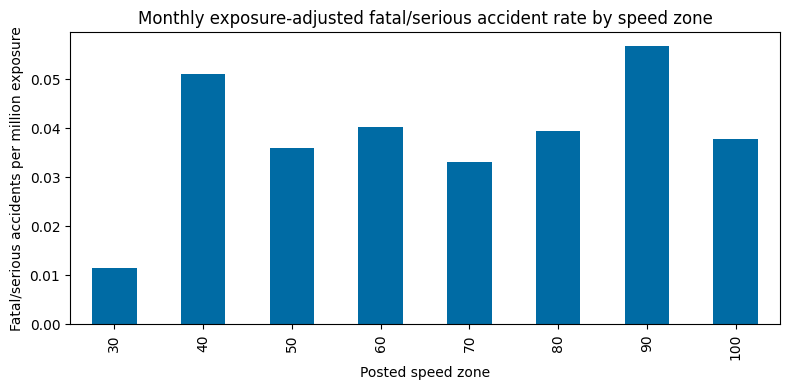

In [28]:
speed_month_summary = (
    monthly_df.groupby(SPEED_COL, dropna=False)
    .agg(
        site_months=(TARGET_COL, "size"),
        fatal_or_serious=(TARGET_COL, "sum"),
        exposure=(EXPOSURE_COL, "sum"),
        mean_monthly_count=(TARGET_COL, "mean"),
    )
    .reset_index()
)
speed_month_summary["fatal_or_serious_per_million_exposure"] = (
    speed_month_summary["fatal_or_serious"] / speed_month_summary["exposure"] * 1_000_000
)
speed_month_summary = speed_month_summary.sort_values(SPEED_COL)
display(speed_month_summary)

ax = speed_month_summary.plot(
    x=SPEED_COL,
    y="fatal_or_serious_per_million_exposure",
    kind="bar",
    legend=False,
    figsize=(8, 4),
)
ax.set_xlabel("Posted speed zone")
ax.set_ylabel("Fatal/serious accidents per million exposure")
ax.set_title("Monthly exposure-adjusted fatal/serious accident rate by speed zone")
plt.tight_layout()
plt.show()


#### Build the modelling matrix

This selects model features and target values. `SITE_SPEED_ZONE_MODE` is kept as the key explanatory variable, while exposure and traffic-volume features act as controls. Accident-count columns are excluded from features to avoid leakage.


In [29]:
feature_candidates = [
    SPEED_COL,
    EXPOSURE_COL,
    "LOG_EXPOSURE_VOLUME",
    "NUM_SITE_DAYS",
    "YEAR",
    "MONTH",
] + traffic_mean_cols

feature_cols = [col for col in feature_candidates if col in monthly_df.columns]
X = monthly_df[feature_cols].copy()
y = monthly_df[TARGET_COL].astype(float)

numeric_features = [col for col in feature_cols if col != SPEED_COL]
categorical_features = [SPEED_COL]

print("Features:", feature_cols)
print("Target:", TARGET_COL)
print("Rows:", len(monthly_df))


Features: ['SITE_SPEED_ZONE_MODE', 'EXPOSURE_VOLUME', 'LOG_EXPOSURE_VOLUME', 'NUM_SITE_DAYS', 'YEAR', 'MONTH', 'SUM_VALID_V', 'V_AM_PEAK', 'V_PM_PEAK', 'V_15M_MAX', 'V_15M_STD', 'NUM_VALID_V', 'NUM_VALID_DETECTOR', 'NUM_RAW_DETECTOR', 'COMPLETENESS', 'DETECTOR_RETENTION']
Target: FATAL_OR_SERIOUS_COUNT
Rows: 531638


#### Split train and test data

This uses a time-based split when there are enough months, so later months become the test set. If the dataset has too few unique months, it falls back to a random split.


In [30]:
unique_months = sorted(monthly_df["YEAR_MONTH"].unique())

if len(unique_months) >= 4:
    cutoff = unique_months[int(len(unique_months) * 0.75)]
    train_mask = monthly_df["YEAR_MONTH"] < cutoff
    test_mask = monthly_df["YEAR_MONTH"] >= cutoff

    X_train, X_test = X.loc[train_mask], X.loc[test_mask]
    y_train, y_test = y.loc[train_mask], y.loc[test_mask]
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=RANDOM_STATE,
    )

print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Train target mean:", y_train.mean())
print("Test target mean:", y_test.mean())


Train rows: 386088
Test rows: 145550
Train target mean: 0.03878131410455647
Test target mean: 0.03347303332188251


#### Define preprocessing and evaluation helpers

This cell creates the shared preprocessing pipeline and a small evaluator. The evaluator clips negative predictions to zero because accident counts cannot be negative.


In [36]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

linear_preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot_encoder()),
        ]), categorical_features),
    ],
    remainder="drop",
)

tree_preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot_encoder()),
        ]), categorical_features),
    ],
    remainder="drop",
)

def evaluate_count_model(name, model, X_test, y_test):
    pred = np.asarray(model.predict(X_test), dtype=float)
    pred = np.clip(pred, 1e-12, None)
    return {
        "model": name,
        "mae": mean_absolute_error(y_test, pred),
        "rmse": mean_squared_error(y_test, pred) ** 0.5,
        "mean_poisson_deviance": mean_poisson_deviance(y_test, pred),
        "pred_mean": pred.mean(),
        "actual_mean": y_test.mean(),
    }


#### Train PoissonRegressor, RandomForest, and XGBoost

This trains the three agreed classical models on monthly accident counts. Poisson regression is the count-model baseline, while RandomForest and XGBoost provide non-linear baselines.


In [37]:
models = {
    "poisson_regressor": Pipeline([
        ("prep", linear_preprocess),
        ("model", PoissonRegressor(alpha=1e-4, max_iter=1000)),
    ]),
    "random_forest": Pipeline([
        ("prep", tree_preprocess),
        ("model", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "xgboost_poisson": Pipeline([
        ("prep", tree_preprocess),
        ("model", XGBRegressor(
            objective="count:poisson",
            n_estimators=400,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

results = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results.append(evaluate_count_model(name, model, X_test, y_test))
    fitted_models[name] = model

model_results = pd.DataFrame(results).sort_values("mean_poisson_deviance")
display(model_results)


,model,mae,rmse,mean_poisson_deviance,pred_mean,actual_mean
2,xgboost_poisson,0.066033,0.184011,0.223549,0.035370,0.033473
0,poisson_regressor,0.065166,0.184084,0.224229,0.034349,0.033473
1,random_forest,0.076888,0.186300,0.236328,0.047217,0.033473


#### Ablation study
compare each classical model with vs without posted speed zone. This checks whether SITE_SPEED_ZONE_MODE adds predictive value after controlling for exposure and traffic features.

In [38]:
def build_preprocess_for(feature_list):
    num_cols = [col for col in feature_list if col != SPEED_COL]
    cat_cols = [col for col in feature_list if col == SPEED_COL]

    linear_transformers = []
    tree_transformers = []

    if num_cols:
        linear_transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            num_cols,
        ))
        tree_transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
            ]),
            num_cols,
        ))

    if cat_cols:
        cat_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot_encoder()),
        ])
        linear_transformers.append(("cat", cat_pipeline, cat_cols))
        tree_transformers.append(("cat", cat_pipeline, cat_cols))

    return (
        ColumnTransformer(linear_transformers, remainder="drop"),
        ColumnTransformer(tree_transformers, remainder="drop"),
    )


def build_ablation_models(feature_list):
    linear_prep, tree_prep = build_preprocess_for(feature_list)
    return {
        "poisson_regressor": Pipeline([
            ("prep", linear_prep),
            ("model", PoissonRegressor(alpha=1e-4, max_iter=1000)),
        ]),
        "random_forest": Pipeline([
            ("prep", tree_prep),
            ("model", RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=5,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
        "xgboost_poisson": Pipeline([
            ("prep", tree_prep),
            ("model", XGBRegressor(
                objective="count:poisson",
                n_estimators=400,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
    }

feature_sets = {
    "with_speed": feature_cols,
    "without_speed": [col for col in feature_cols if col != SPEED_COL],
}

ablation_rows = []
for setting, cols in feature_sets.items():
    ablation_models = build_ablation_models(cols)
    for model_name, model in ablation_models.items():
        model.fit(X_train[cols], y_train)
        row = evaluate_count_model(model_name, model, X_test[cols], y_test)
        row["setting"] = setting
        row["n_features"] = len(cols)
        ablation_rows.append(row)

ablation_results = pd.DataFrame(ablation_rows)
metric_cols = ["mae", "rmse", "mean_poisson_deviance"]

ablation_delta = (
    ablation_results
    .pivot(index="model", columns="setting", values=metric_cols)
)
for metric in metric_cols:
    ablation_delta[(metric, "improvement_from_speed")] = (
        ablation_delta[(metric, "without_speed")] - ablation_delta[(metric, "with_speed")]
    )

ablation_delta = ablation_delta.sort_values(("mean_poisson_deviance", "improvement_from_speed"), ascending=False)

display(ablation_results.sort_values(["model", "setting"]))
display(ablation_delta)

out_dir = DATA_PATH.parent
ablation_results.to_csv(out_dir / "rq2_speed_ablation_results.csv", index=False)
ablation_delta.to_csv(out_dir / "rq2_speed_ablation_delta.csv")
print("Saved ablation results to", out_dir.resolve())


,model,mae,rmse,mean_poisson_deviance,pred_mean,actual_mean,setting,n_features
0,poisson_regressor,0.065166,0.184084,0.224229,0.034349,0.033473,with_speed,16
3,poisson_regressor,0.065336,0.184123,0.224638,0.034512,0.033473,without_speed,15
1,random_forest,0.076888,0.186300,0.236328,0.047217,0.033473,with_speed,16
4,random_forest,0.076745,0.186309,0.236535,0.047012,0.033473,without_speed,15
2,xgboost_poisson,0.066033,0.184011,0.223549,0.035370,0.033473,with_speed,16
5,xgboost_poisson,0.066129,0.184060,0.223946,0.035446,0.033473,without_speed,15


mae                     rmse                \
setting           with_speed without_speed with_speed without_speed   
model                                                                 
poisson_regressor   0.065166      0.065336   0.184084      0.184123   
xgboost_poisson     0.066033      0.066129   0.184011      0.184060   
random_forest       0.076888      0.076745   0.186300      0.186309   

                  mean_poisson_deviance                                  mae  \
setting                      with_speed without_speed improvement_from_speed   
model                                                                          
poisson_regressor              0.224229      0.224638               0.000170   
xgboost_poisson                0.223549      0.223946               0.000097   
random_forest                  0.236328      0.236535              -0.000142   

                                    rmse  mean_poisson_deviance  
setting           improvement_from_speed improvement_from_speed  
model                                                            
poisson_regressor               0.000038               0.000409  
xgboost_poisson                 0.000049               0.000397  
random_forest                   0.000009               0.000207

Saved ablation results to D:\UniMelb\2026 s1\COMP 90049 Introduction to Machine Learning\A2\a2


#### Inspect which features RandomForest uses most

This gives a rough feature-importance view from RandomForest. It is not causal evidence, but it helps explain whether speed zone and exposure-related variables are influential in the non-linear baseline.


In [33]:
rf_pipeline = fitted_models["random_forest"]
rf_prep = rf_pipeline.named_steps["prep"]
rf_model = rf_pipeline.named_steps["model"]

try:
    feature_names = rf_prep.get_feature_names_out()
except Exception:
    feature_names = np.array([f"feature_{i}" for i in range(len(rf_model.feature_importances_))])

rf_importance = (
    pd.DataFrame({"feature": feature_names, "importance": rf_model.feature_importances_})
    .sort_values("importance", ascending=False)
    .head(20)
)
display(rf_importance)


,feature,importance
6,num__V_AM_PEAK,0.128368
9,num__V_15M_STD,0.121424
7,num__V_PM_PEAK,0.117806
8,num__V_15M_MAX,0.116640
5,num__SUM_VALID_V,0.111015
13,num__COMPLETENESS,0.064811
10,num__NUM_VALID_V,0.064671
1,num__LOG_EXPOSURE_VOLUME,0.062427
0,num__EXPOSURE_VOLUME,0.062227
4,num__MONTH,0.040484


#### Save monthly modelling outputs

This saves the monthly modelling table, the speed-zone summary, model metrics, and feature-importance table.


In [34]:
out_dir = DATA_PATH.parent
monthly_df.to_csv(out_dir / "rq2_monthly_model_table.csv", index=False)
speed_month_summary.to_csv(out_dir / "rq2_monthly_speed_rate_summary.csv", index=False)
model_results.to_csv(out_dir / "rq2_monthly_classical_model_results.csv", index=False)
rf_importance.to_csv(out_dir / "rq2_random_forest_feature_importance.csv", index=False)
print("Saved monthly RQ2 outputs to", out_dir.resolve())


Saved monthly RQ2 outputs to D:\UniMelb\2026 s1\COMP 90049 Introduction to Machine Learning\A2\a2
